In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['SYNTH_GRIDSEARCH']='1'
os.environ['SYNTH_NATIVE_COMPARE']='0'
os.environ['SYNTH_NATIVE_LAYOUT']='0'
os.environ['SYNTH_NATIVE_SIM']='0'
os.environ['SYNTH_TEMPORAL']='0'
os.environ['SYNTH_SWEEP']='0'
os.environ['SYNTH_BLURSWEEP']='0'
os.environ['QR_NATGALLERY']='0'
os.environ['DSBUILD_RUN']='1'
os.environ['DS_TARGET_GB']='18.5'
os.environ['DS_SEQ_LEN']='6'
os.environ['DS_SEQ_FRAC']='0.35'
os.environ['DS_BUDGET_H']='7.5'
os.environ['DS_DIV_RATE']='0.05'
os.environ['SYNTH_PLACE_MODE']='shell'
os.environ['SYNTH_EDGE_FRAC']='0.35'

In [3]:
import os, sys, json, glob, math, subprocess, importlib.util as _ilu
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import (
    gaussian_filter,
    maximum_filter,
    zoom as ndzoom,
    convolve as ndconvolve,
)

In [49]:

OUT = Path("synth_out_3")
DSDIR = OUT / "synth_dataset"
(DSDIR).mkdir(parents=True, exist_ok=True)
FIG = OUT / "figuras_synth"
FIG.mkdir(parents=True, exist_ok=True)

### [D] SHOWCASE — visual documentation of the generator
Three rich outputs: **(1)** the step-by-step PIPELINE (how a volume is built),
**(2)** GALLERY of real vs synthetic cells, **(3)** hypothesis test REPORT
(8 distributions: KS + energy distance + Anderson-Darling, with a verdict per distribution).

In [50]:
N_STATIC = 10000
N_SEQ = 10

In [51]:
import os, json, time
import numpy as np
from tqdm import tqdm

from utils import pool_xy, dog_detect_precise, norm, read_frame

def _to_u16(v):
    """float [0,1] -> uint16. Halves the size versus float32 with no visible loss (the real data is
    uint16 as well)."""
    return np.clip(v * 65535.0, 0, 65535).astype(np.uint16)


def _real_stats(td, vids, n_frames=2):
    """REAL per-field count distribution + tissue-shell geometry (drives the generative placement)."""
    counts, pts = [], []
    for name in vids:
        for t in range(n_frames):
            # try:
            vp = pool_xy(norm(read_frame(td / f"{name}.zarr", t)[0]))  # noqa: F821
            # except Exception:
            #     continue
            d = dog_detect_precise(vp)[0]  # noqa: F821
            counts.append(len(d))
            if len(d) and len(pts) < 8:
                pts.append(np.atleast_2d(d) * np.array([1, POOL, POOL]))  # noqa: F821
    shell = fit_shell(np.concatenate(pts)) if pts else None  # noqa: F821
    return np.array(counts, float), shell


In [52]:
from main import gen_volume_native

In [53]:
from joblib import Parallel, delayed
from tqdm import tqdm
import numpy as np


def generate_static_volume(i, counts, shell, out_dir):
    rg = np.random.default_rng(100000 + i)
    nc = int(max(20, rg.choice(counts) * 1.25))

    nat, _, cen, _, mask = gen_volume_native(
        zshape=64,
        xyshape=256,
        n_cells=nc,
        rng=rg,
        shell=shell,
    )

    # return nat, mask, cen

    relative_file = f"static/vol_{i:05d}.npz"
    fp = out_dir / relative_file

    np.savez(
        fp,
        volume=_to_u16(nat),
        mask=mask,
        centroids=cen.astype(np.float32),
        voxel_um=np.array(
            [1.625, 0.40625, 0.40625],
            dtype=np.float32,
        ),
    )

    sz = fp.stat().st_size

    return {
        "index": i,
        "file": relative_file,
        "n_cells": int(len(cen)),
        "shape": list(nat.shape),
        "bytes": int(sz),
    }


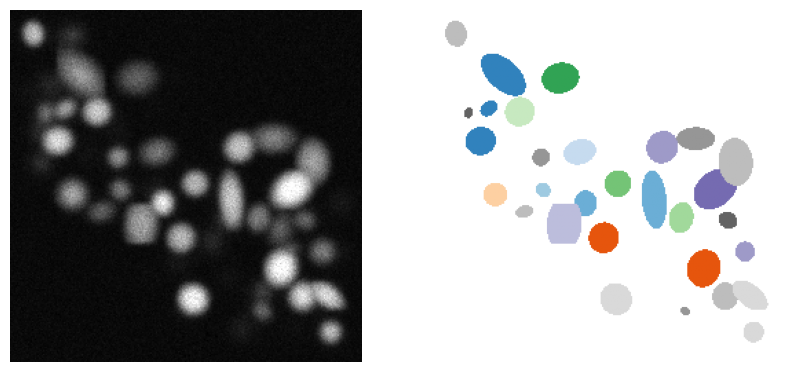

In [54]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(nat[32], cmap="gray")
plt.axis(False)
plt.subplot(1, 2, 2)
plt.imshow(np.where(mask[32]>0, mask[32], np.nan), cmap="tab20c")
plt.axis(False)
plt.show()

#### Static

In [55]:
OUTD = OUT / "biohub_synthetic"  # noqa: F821
(OUTD / "static").mkdir(parents=True, exist_ok=True)
(OUTD / "sequences").mkdir(parents=True, exist_ok=True)

td = find_train_dir()
assert td, "train directory not found"  # noqa: F821
vids = sorted(p.stem for p in td.glob("*.zarr"))
by = {}
for v in vids:
    by.setdefault(v.split("_")[0], []).append(v)
embs = sorted(by)
# Calibrate on one embryo only, leaving the other free for the user's own validation.
calib = sorted(by[embs[0]])[:10]

In [56]:
counts, shell = _real_stats(td, calib)
print(
    f"=== PUBLIC DATASET | real density {counts.min():.0f}-{counts.max():.0f} "
    f"| shell {shell['kind'] if shell else '?'} ===",
    flush=True,
)

TARGET = float(os.environ.get("DS_TARGET_GB", "18.5")) * (
    1024**3
)  # margin under the 20 GB ceiling
T_SEQ = int(os.environ.get("DS_SEQ_LEN", "6"))
SEQ_FRAC = float(
    os.environ.get("DS_SEQ_FRAC", "0.35")
)  # share of the budget spent on sequences
BUDGET_S = float(os.environ.get("DS_BUDGET_H", "8.5")) * 3600
os.environ.setdefault("SYNTH_PLACE_MODE", "shell")
t0 = time.time()
total = 0

=== PUBLIC DATASET | real density 140-417 | shell plane ===


In [57]:
from utils import find_train_dir

In [58]:
results = []
for i in tqdm(range(10)):
    results.append(generate_static_volume(i, counts, shell, OUTD))

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:26<00:00,  2.63s/it]


In [61]:
results = Parallel(
    n_jobs=16,
    # backend="loky",
)(
    delayed(generate_static_volume)(i, counts, shell, OUTD)
    for i in tqdm(
        range(N_STATIC),
        desc="submitting static volumes",
    )
)

submitting static volumes: 100%|██████████| 10000/10000 [18:43<00:00,  8.90it/s]


In [ ]:
results.sort(key=lambda item: item["index"])
json.dump(results, open(OUTD / "results_static.json", "w"), indent=2, default=float)

In [ ]:

# # ---------------- B) TIME SEQUENCES WITH LINEAGE ----------------
# # Motion is calibrated on the REAL lineage edges of the .geff files: median step 1.86 um/frame
# # (p90 3.83), lag-1 directional persistence +0.30, sister separation ~7.24 um. Division is
# # DELIBERATELY over-sampled: it is the supervision that is scarce in the real data (~0.26% of
# # nodes) and the main reason this dataset exists.
# STEP_MED, PERSIST, SISTER = 1.86, 0.30, 7.24
# VOX = np.array([1.625, 0.40625, 0.40625])
# s_step = (STEP_MED / 1.5382) * 1.10

# manifest = {"static": [], "sequences": []}

# for j in tqdm(range(N_SEQ), desc="time sequences"):
#     rg = np.random.default_rng(500000 + j)
#     n0 = int(max(20, rg.choice(counts) * 1.25))
#     pos, radii = sample_shell_positions(
#         n0, (64, 256, 256), rg, shell=shell, r_lo=3.5, r_hi=5.5  # noqa: F821
#     )
#     if len(pos) < 10:
#         j += 1
#         continue
#     # per-cell speed scale (log-normal) reproduces the heavy tail of the real step distribution
#     sc = np.exp(rg.normal(0, 0.55, len(pos)))
#     vel = rg.normal(0, s_step, (len(pos), 3)) * sc[:, None]
#     flow = rg.normal(0, 1, 3)
#     flow /= np.linalg.norm(flow) + 1e-9  # collective tissue drift
#     div_p = float(
#         os.environ.get("DS_DIV_RATE", "0.05")
#     )  # over-sampled (real ~0.0026)
#     tracks = [
#         dict(pos=p.copy(), vel=vel[k], sc=sc[k], tid=k) for k, p in enumerate(pos)
#     ]
#     nodes, edges, divs = [], [], []
#     vols = np.zeros((T_SEQ, 64, 256, 256), np.uint16)  # pooled, to fit the budget
#     nid = 0
#     prev_ids = {}
#     for t in range(T_SEQ):
#         cens = np.array([tr["pos"] for tr in tracks], np.float32)
#         nat, _, cc, _ = gen_volume_native(
#             zshape=64,
#             xyshape=256,
#             cens_native=cens,  # noqa: F821
#             rng=np.random.default_rng(900000 + j * 97 + t),
#             shell=shell,
#         )
#         vols[t] = _to_u16(nat)  # noqa: F821
#         cur_ids = {}
#         for k, tr in enumerate(tracks):
#             nodes.append([t, tr["pos"][0], tr["pos"][1], tr["pos"][2], tr["tid"]])
#             cur_ids[k] = nid
#             nid += 1
#         for k, tr in enumerate(tracks):
#             if tr.get("parent_slot") is not None and tr["parent_slot"] in prev_ids:
#                 edges.append([prev_ids[tr["parent_slot"]], cur_ids[k]])
#                 if tr.get("is_div"):
#                     divs.append(prev_ids[tr["parent_slot"]])
#         prev_ids = cur_ids
#         if t == T_SEQ - 1:
#             break
#         nxt = []
#         for k, tr in enumerate(tracks):
#             # Ornstein-Uhlenbeck step: persistent velocity + collective flow
#             v = PERSIST * tr["vel"] + np.sqrt(1 - PERSIST**2) * rg.normal(
#                 0, s_step * tr["sc"], 3
#             )
#             v = v + 0.35 * s_step * flow
#             if rg.random() < div_p:  # DIVISION
#                 d = rg.normal(0, 1, 3)
#                 d /= np.linalg.norm(d) + 1e-9
#                 half = 0.5 * max(2.0, rg.normal(SISTER, 1.6)) * d / VOX
#                 for sgn in (1, -1):
#                     p2 = np.clip(
#                         tr["pos"] + v + sgn * half, [4, 12, 12], [59, 243, 243]
#                     )
#                     nxt.append(
#                         dict(
#                             pos=p2,
#                             vel=v * 0.5,
#                             sc=tr["sc"],
#                             tid=tr["tid"],
#                             parent_slot=k,
#                             is_div=True,
#                         )
#                     )
#             else:
#                 p2 = np.clip(tr["pos"] + v, [4, 12, 12], [59, 243, 243])
#                 nxt.append(
#                     dict(
#                         pos=p2,
#                         vel=v,
#                         sc=tr["sc"],
#                         tid=tr["tid"],
#                         parent_slot=k,
#                         is_div=False,
#                     )
#                 )
#         tracks = nxt
#     fp = OUTD / "sequences" / f"seq_{j:04d}.npz"
#     np.savez(
#         fp,
#         volumes=vols,
#         nodes=np.array(nodes, np.float32),
#         edges=np.array(edges, np.int32),
#         divisions=np.array(sorted(set(divs)), np.int32),
#         voxel_um_pooled=np.array([1.625, 1.625, 1.625], np.float32),
#     )
#     sz = fp.stat().st_size
#     total += sz
#     manifest["sequences"].append(
#         dict(
#             file=f"sequences/seq_{j:04d}.npz",
#             T=int(T_SEQ),
#             n_nodes=len(nodes),
#             n_edges=len(edges),
#             n_divisions=len(set(divs)),
#             bytes=int(sz),
#         )
#     )

# nd = sum(m["n_divisions"] for m in manifest["sequences"])
# nn = sum(m["n_nodes"] for m in manifest["sequences"])
# meta = dict(
#     n_static=i,
#     n_sequences=j,
#     total_gb=total / 1024**3,
#     seq_len=T_SEQ,
#     total_divisions=nd,
#     total_nodes=nn,
#     division_rate=nd / max(nn, 1),
#     voxel_native_um=[1.625, 0.40625, 0.40625],
#     pooling="stride 4x in XY (vol[:, ::4, ::4]) -- identical to the official evaluator",
#     real_count_range=[float(counts.min()), float(counts.max())],
#     shell_kind=(shell or {}).get("kind"),
#     motion_calibration=dict(
#         median_step_um_per_frame=STEP_MED,
#         lag1_persistence=PERSIST,
#         sister_separation_um=SISTER,
#     ),
#     note_division_rate="Divisions are deliberately over-sampled; the real ground-truth rate is "
#     "about 0.26% of nodes. Re-weight your loss if you need calibrated priors.",
#     config={k: v for k, v in os.environ.items() if k.startswith("SYNTH_")},
# )
# json.dump(meta, open(OUTD / "metadata.json", "w"), indent=2, default=float)
# json.dump(manifest, open(OUTD / "manifest.json", "w"), indent=2, default=float)
# print(
#     f"\n  labelled divisions: {nd} across {nn} nodes ({100*nd/max(nn,1):.2f}%) "
#     f"-- the real ground truth holds ~0.26%",
#     flush=True,
# )
# print(f"  -> {OUTD}", flush=True)

Done !